# CS 463 Project — Data Preparation

This notebook prepares the M5 retail dataset for machine learning models.

**Scenario:** a store manager places a replenishment order once a week. On the
order date they need a forecast of daily unit sales for each product for the
coming week. That means the model may only use information that is known on
the order date — so every sales-based feature is lagged by at least
`HORIZON` days.

**Pipeline order** (each step depends on the previous one):

1. Load the raw data and reshape sales from wide to long
2. Merge calendar and price information
3. Investigate and remove rows where the product was not yet on sale
4. Engineer calendar, event, price, and product features
5. Engineer lag and rolling features (after filtering, so they are computed
   only on the product's real selling history)
6. Chronological train / validation / test split and save

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Forecast horizon in days: sales features must be at least this old.
HORIZON = 7

# A single store keeps the dataset manageable (~4.6M rows).
STORE = "CA_1"

calendar = pd.read_csv("calendar.csv")
sales = pd.read_csv("sales_train_validation.csv")
prices = pd.read_csv("sell_prices.csv")

print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

Calendar: (1969, 14)
Sales: (30490, 1919)
Prices: (6841121, 4)


The M5 dataset contains three main sources:

- `sales_train_validation.csv`: historical unit sales
- `calendar.csv`: dates, weekdays, events, and SNAP information
- `sell_prices.csv`: weekly product selling prices

## 1. Reshape sales from wide to long

In [2]:
sales_subset = sales[
    sales["store_id"] == STORE
].copy()

day_cols = [
    col for col in sales.columns
    if col.startswith("d_")
]

print("Store subset:", sales_subset.shape)
print("Number of sales days:", len(day_cols))

sales_long = sales_subset.melt(
    id_vars=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=day_cols,
    var_name="d",
    value_name="sales"
)

print("Long format:", sales_long.shape)
sales_long.head()

Store subset: (3049, 1919)
Number of sales days: 1913
Long format: (5832737, 8)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


## 2. Merge calendar and prices

Price changes are computed on the weekly price table *before* merging, so
each change is measured between consecutive weeks of the same product.

In [3]:
model_data = sales_long.merge(
    calendar,
    on="d",
    how="left"
)

model_data["date"] = pd.to_datetime(
    model_data["date"]
)

prices = prices.sort_values([
    "store_id",
    "item_id",
    "wm_yr_wk"
]).copy()

price_groups = prices.groupby([
    "store_id",
    "item_id"
])["sell_price"]

prices["price_change"] = price_groups.diff()

prices["price_pct_change"] = (
    price_groups.pct_change(fill_method=None)
)

model_data = model_data.merge(
    prices,
    on=[
        "store_id",
        "item_id",
        "wm_yr_wk"
    ],
    how="left"
)

print(model_data.shape)
model_data.isnull().sum().sort_values(
    ascending=False
).head(8)

(5832737, 24)


event_type_2        5820541
event_name_2        5820541
event_type_1        5363191
event_name_1        5363191
price_pct_change    1151185
price_change        1151185
sell_price          1129842
item_id                   0
dtype: int64

## 3. Missing prices: products not yet on sale

About 19% of rows have no price. Before removing them, we check *why* they
are missing.

In [4]:
missing = model_data["sell_price"].isna()

print("Missing price percentage:", round(missing.mean() * 100, 2))
print(
    "Missing-price rows with positive sales:",
    (model_data.loc[missing, "sales"] > 0).sum()
)

first_price = (
    model_data[~missing]
    .groupby(["store_id", "item_id"])["date"]
    .min()
    .rename("first_price_date")
)

missing_rows = model_data[missing].join(
    first_price,
    on=["store_id", "item_id"]
)

print(
    "Missing before first price:",
    (missing_rows["date"] < missing_rows["first_price_date"]).sum()
)
print(
    "Missing after first price:",
    (missing_rows["date"] >= missing_rows["first_price_date"]).sum()
)
print(
    "No recorded price ever:",
    missing_rows["first_price_date"].isna().sum()
)

Missing price percentage: 19.37
Missing-price rows with positive sales: 0
Missing before first price: 1129842
Missing after first price: 0
No recorded price ever: 0


Every missing price occurs **before the product's first recorded price**, and
every one of those rows has zero sales. These rows mean "the product was not
on the shelf yet", not real zero demand. Keeping them would teach the model
that these products had no demand, so we remove them.

This is done *before* computing lag and rolling features. Otherwise a newly
launched product's early rolling averages would be diluted by pre-launch zeros.

In [5]:
print("Before filtering:", model_data.shape)

model_data = model_data[
    model_data["sell_price"].notna()
].copy()

print("After filtering:", model_data.shape)

# A product's first recorded price has no previous price to compare with
model_data["price_change"] = (
    model_data["price_change"].fillna(0)
)

model_data["price_pct_change"] = (
    model_data["price_pct_change"].fillna(0)
)

Before filtering: (5832737, 24)
After filtering: (4702895, 24)


## 4. Calendar, event, and product features

- `is_event_day`: any named event on this date
- `event_type_*`: one-hot event type (Cultural, National, Religious, Sporting)
- `days_until_event`: days until the next named event — sales often change in
  the days *leading up to* a holiday, not just on the day itself
- `is_weekend`
- `snap`: SNAP benefits day for the store's own state
- One-hot `wday`, `month`, `dept_id`, and `cat_id`, so linear models do not
  treat month 12 as "larger" than month 1, and so the model can tell product
  departments apart

In [6]:
event_cols = [
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2"
]

model_data[event_cols] = (
    model_data[event_cols]
    .fillna("No Event")
)

model_data["is_event_day"] = (
    (model_data["event_name_1"] != "No Event") |
    (model_data["event_name_2"] != "No Event")
).astype("int8")

for event_type in ["Cultural", "National", "Religious", "Sporting"]:
    model_data[f"event_type_{event_type}"] = (
        (model_data["event_type_1"] == event_type) |
        (model_data["event_type_2"] == event_type)
    ).astype("int8")

In [7]:
# Days until the next named event, computed once on the calendar
cal_dates = pd.to_datetime(calendar["date"])
event_dates = cal_dates[calendar["event_name_1"].notna()].values

next_idx = np.searchsorted(event_dates, cal_dates.values, side="left")
has_next = next_idx < len(event_dates)

days_until = np.full(len(calendar), np.nan)
days_until[has_next] = (
    (event_dates[next_idx[has_next]] - cal_dates.values[has_next])
    / np.timedelta64(1, "D")
)

days_until_event = pd.Series(days_until, index=cal_dates)

model_data["days_until_event"] = (
    model_data["date"].map(days_until_event)
)

model_data[["date", "event_name_1", "days_until_event"]].drop_duplicates(
    "date"
).sort_values("date").head(20)

,date,event_name_1,days_until_event
7,2011-01-29,No Event,8.0
3056,2011-01-30,No Event,7.0
6105,2011-01-31,No Event,6.0
9154,2011-02-01,No Event,5.0
12203,2011-02-02,No Event,4.0
15252,2011-02-03,No Event,3.0
18301,2011-02-04,No Event,2.0
21350,2011-02-05,No Event,1.0
24399,2011-02-06,SuperBowl,0.0
27448,2011-02-07,No Event,7.0


In [8]:
model_data["is_weekend"] = (
    model_data["weekday"]
    .isin(["Saturday", "Sunday"])
    .astype("int8")
)

# Use the SNAP flag that matches each row's state
model_data["snap"] = np.select(
    [
        model_data["state_id"] == "CA",
        model_data["state_id"] == "TX",
        model_data["state_id"] == "WI",
    ],
    [
        model_data["snap_CA"],
        model_data["snap_TX"],
        model_data["snap_WI"],
    ],
    default=0
).astype("int8")

In [9]:
one_hot = pd.get_dummies(
    model_data[["wday", "month", "dept_id", "cat_id"]].astype(str),
    prefix=["wday", "month", "dept", "cat"],
    dtype="int8"
)

model_data = pd.concat([model_data, one_hot], axis=1)

one_hot_columns = list(one_hot.columns)
print(len(one_hot_columns), "one-hot columns:")
print(one_hot_columns)

29 one-hot columns:
['wday_1', 'wday_2', 'wday_3', 'wday_4', 'wday_5', 'wday_6', 'wday_7', 'month_1', 'month_10', 'month_11', 'month_12', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'dept_FOODS_1', 'dept_FOODS_2', 'dept_FOODS_3', 'dept_HOBBIES_1', 'dept_HOBBIES_2', 'dept_HOUSEHOLD_1', 'dept_HOUSEHOLD_2', 'cat_FOODS', 'cat_HOBBIES', 'cat_HOUSEHOLD']


## 5. Lag and rolling features

Because the store orders a week ahead, the most recent sales the model can
see are `HORIZON` days old. So:

- lags start at `HORIZON` (with `HORIZON = 7`: 7, 14, 21, and 28 days)
- rolling statistics are computed on sales shifted by `HORIZON` days

This prevents the model from using sales it would not know on the order date,
which would make results look better than they would be in practice.

In [10]:
model_data = model_data.sort_values(
    [
        "store_id",
        "item_id",
        "date"
    ]
).reset_index(drop=True)

groups = model_data.groupby(
    [
        "store_id",
        "item_id"
    ],
    group_keys=False
)

lag_days = sorted({
    lag for lag in [HORIZON, 14, 21, 28]
    if lag >= HORIZON
})

lag_columns = []

for lag in lag_days:
    column = f"sales_lag_{lag}"
    model_data[column] = groups["sales"].shift(lag)
    lag_columns.append(column)

print("Lag features:", lag_columns)

Lag features: ['sales_lag_7', 'sales_lag_14', 'sales_lag_21', 'sales_lag_28']


In [11]:
model_data["rolling_mean_7"] = (
    groups["sales"]
    .transform(
        lambda x:
        x.shift(HORIZON)
         .rolling(7)
         .mean()
    )
)

model_data["rolling_mean_28"] = (
    groups["sales"]
    .transform(
        lambda x:
        x.shift(HORIZON)
         .rolling(28)
         .mean()
    )
)

model_data["rolling_std_7"] = (
    groups["sales"]
    .transform(
        lambda x:
        x.shift(HORIZON)
         .rolling(7)
         .std()
    )
)

rolling_columns = [
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_7"
]

The first rows of each product's history do not have enough past sales to
fill the lag and rolling windows, so they are dropped.

In [12]:
model_data["target_sales"] = model_data["sales"]

print("Before dropping incomplete history:", model_data.shape)

model_data = model_data.dropna(
    subset=lag_columns + rolling_columns + ["days_until_event"]
).copy()

print("After dropping incomplete history:", model_data.shape)

Before dropping incomplete history: (4702895, 69)
After dropping incomplete history: (4599229, 69)


## 6. Store closures and suspected stockouts

**Christmas.** The store is closed on December 25: every product records 0
sales. There is no demand to forecast, so these rows are removed. They are
removed *after* the lag features are built, because the lags count back by
rows and need every calendar day present.

**Suspected stockouts.** Most zeros are real — 60% of products sell less than
one unit a day. But some zeros happen because the product was out of stock,
not because nobody wanted it. M5 has no inventory data, so we *infer* likely
stockouts from improbable zero streaks:

1. Find each run of consecutive zero-sales days for a product.
2. Take the product's normal sales rate from `rolling_mean_28` at the start of
   the run (average daily sales over the 28 days ending `HORIZON` days earlier).
3. If sales are roughly Poisson, the probability of seeing `L` zeros in a row
   at rate `r` is `exp(-r * L)`.
4. If that probability is below `STOCKOUT_P`, every day in the run is flagged.

For example, a product that normally sells 100 units a day and then records
4 zeros in a row is almost certainly out of stock.

The flag is used **only to choose training rows**, never as a model feature —
it uses the length of the whole run, which is not known on the order date.
Flagged rows are kept in the saved files so the test set can be scored both
on all rows and on non-stockout rows.

In [13]:
is_christmas = (
    (model_data["date"].dt.month == 12)
    & (model_data["date"].dt.day == 25)
)

print("Christmas rows:", is_christmas.sum())
print("Christmas rows with sales:", (model_data.loc[is_christmas, "sales"] > 0).sum())

model_data = model_data[~is_christmas].copy()

print("After removing Christmas:", model_data.shape)

Christmas rows: 12570
Christmas rows with sales: 0
After removing Christmas: (4586659, 69)


In [14]:
STOCKOUT_P = 0.001

is_zero = model_data["sales"].eq(0)
same_item = model_data["item_id"].eq(model_data["item_id"].shift())

# A new run starts at a zero whose previous row is not a zero of the same item
run_start = is_zero & ~(is_zero.shift(fill_value=False) & same_item)
run_id = run_start.cumsum().where(is_zero)

zero_runs = model_data[is_zero].groupby(run_id[is_zero]).agg(
    run_length=("sales", "size"),
    normal_rate=("rolling_mean_28", "first")
)

zero_runs["stockout_prob"] = np.exp(
    -zero_runs["normal_rate"] * zero_runs["run_length"]
)

model_data["zero_run_length"] = run_id.map(zero_runs["run_length"])
model_data["stockout_prob"] = run_id.map(zero_runs["stockout_prob"])

model_data["is_suspected_stockout"] = (
    model_data["stockout_prob"] < STOCKOUT_P
).astype("int8")

flagged = model_data["is_suspected_stockout"] == 1

print("Zero-sales runs:", len(zero_runs))
print(
    "Suspected stockout runs:",
    (zero_runs["stockout_prob"] < STOCKOUT_P).sum()
)
print(
    f"Flagged rows: {flagged.sum():,} "
    f"({flagged.mean():.1%} of rows, "
    f"{flagged.sum() / is_zero.sum():.1%} of zero-sales rows)"
)

Zero-sales runs: 659032
Suspected stockout runs: 32901
Flagged rows: 775,890 (16.9% of rows, 30.6% of zero-sales rows)


How sensitive is the flag to the cutoff? A stricter cutoff flags fewer rows.

In [15]:
for cutoff in [0.0001, 0.001, 0.01]:
    share = (model_data["stockout_prob"] < cutoff).mean()
    print(f"STOCKOUT_P = {cutoff}: {share:.1%} of rows flagged")

STOCKOUT_P = 0.0001: 15.1% of rows flagged
STOCKOUT_P = 0.001: 16.9% of rows flagged
STOCKOUT_P = 0.01: 20.9% of rows flagged


In [16]:
flagged_runs = zero_runs[zero_runs["stockout_prob"] < STOCKOUT_P]

length_bins = pd.cut(
    flagged_runs["run_length"],
    [0, 3, 7, 28, 90, np.inf],
    labels=["1-3 days", "4-7 days", "8-28 days", "29-90 days", "90+ days"]
)

print("Flagged rows by category:")
print(model_data.loc[flagged, "cat_id"].value_counts())

flagged_runs.groupby(length_bins, observed=True)["run_length"].agg(
    runs="size",
    zero_days="sum"
)

Flagged rows by category:
cat_id
FOODS        434438
HOUSEHOLD    231126
HOBBIES      110326
Name: count, dtype: int64


,runs,zero_days
run_length,,
1-3 days,10503,20313
4-7 days,7951,43040
8-28 days,8548,121059
29-90 days,3466,186924
90+ days,2433,404554


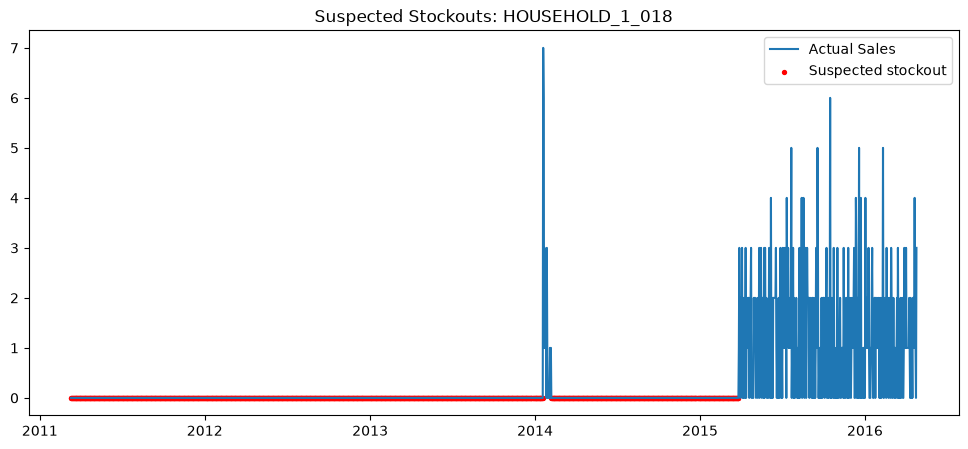

In [17]:
# Example: the product with the most flagged days
example_stockout_item = (
    model_data.loc[flagged, "item_id"].value_counts().index[0]
)

example = model_data[
    model_data["item_id"] == example_stockout_item
]

plt.figure(figsize=(12, 5))

plt.plot(
    example["date"],
    example["sales"],
    label="Actual Sales"
)

plt.scatter(
    example.loc[example["is_suspected_stockout"] == 1, "date"],
    example.loc[example["is_suspected_stockout"] == 1, "sales"],
    color="red",
    s=8,
    label="Suspected stockout"
)

plt.legend()
plt.title(f"Suspected Stockouts: {example_stockout_item}")
plt.show()

### Sanity check: features only use past information

For one product, `sales_lag_7` on each date should equal `sales` exactly
seven rows earlier.

In [18]:
example_item = model_data[
    model_data["item_id"] == model_data["item_id"].iloc[0]
]

example_item[
    [
        "date",
        "sales",
        "sales_lag_7",
        "sales_lag_14",
        "rolling_mean_7"
    ]
].head(15)

,date,sales,sales_lag_7,sales_lag_14,rolling_mean_7
34,2011-03-04,1,4.0,2.0,1.857143
35,2011-03-05,2,2.0,1.0,2.000000
36,2011-03-06,3,2.0,2.0,2.000000
37,2011-03-07,0,0.0,0.0,2.000000
38,2011-03-08,1,2.0,2.0,2.000000
39,2011-03-09,2,1.0,2.0,1.857143
40,2011-03-10,3,7.0,2.0,2.571429
41,2011-03-11,0,1.0,4.0,2.142857
42,2011-03-12,1,2.0,2.0,2.142857
43,2011-03-13,5,3.0,2.0,2.285714


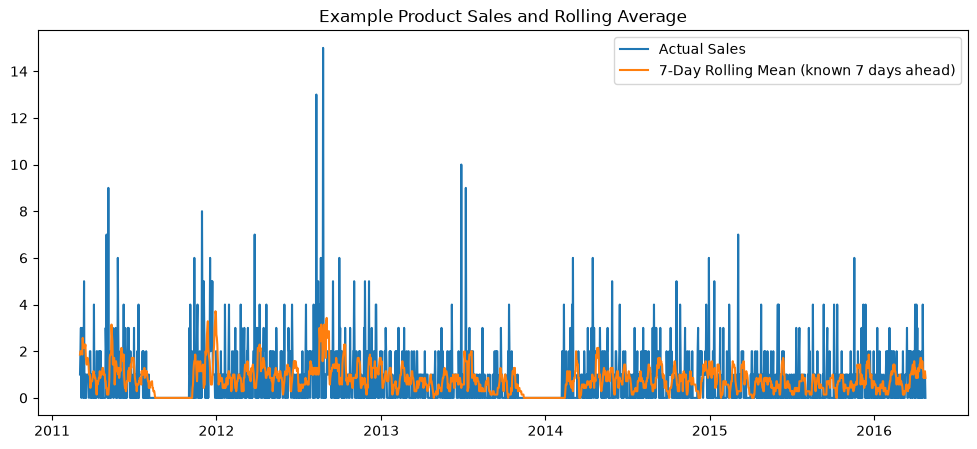

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    example_item["date"],
    example_item["sales"],
    label="Actual Sales"
)

plt.plot(
    example_item["date"],
    example_item["rolling_mean_7"],
    label=f"7-Day Rolling Mean (known {HORIZON} days ahead)"
)

plt.legend()
plt.title(
    "Example Product Sales and Rolling Average"
)
plt.show()

## Final feature list

| Group | Features |
|---|---|
| Recent demand | `sales_lag_*`, `rolling_mean_7`, `rolling_mean_28`, `rolling_std_7` |
| Price | `sell_price`, `price_change`, `price_pct_change` |
| Calendar | `wday_*`, `month_*`, `is_weekend`, `snap` |
| Events | `is_event_day`, `event_type_*`, `days_until_event` |
| Product | `dept_*`, `cat_*` |

The list is saved to `feature_columns.json` so the modeling notebook uses
exactly the same features.

In [20]:
feature_columns = (
    lag_columns
    + rolling_columns
    + [
        "sell_price",
        "price_change",
        "price_pct_change",
        "is_weekend",
        "snap",
        "is_event_day",
        "event_type_Cultural",
        "event_type_National",
        "event_type_Religious",
        "event_type_Sporting",
        "days_until_event",
    ]
    + one_hot_columns
)

# Smaller dtypes cut memory roughly in half
float_cols = model_data.select_dtypes("float64").columns
model_data[float_cols] = model_data[float_cols].astype("float32")
model_data["sales"] = model_data["sales"].astype("int16")
model_data["target_sales"] = model_data["target_sales"].astype("int16")

missing_features = model_data[feature_columns].isna().sum()
assert missing_features.sum() == 0, missing_features[missing_features > 0]

with open("feature_columns.json", "w") as f:
    json.dump(feature_columns, f, indent=2)

print(len(feature_columns), "features, no missing values")
print(model_data.shape)

47 features, no missing values
(4586659, 72)


## 7. Chronological train / validation / test split

I use a chronological split instead of a random train/test split.

This ensures that the model is trained using past observations and evaluated
using future observations, which better represents a real forecasting task
and prevents future-data leakage.

In [21]:
dates = (
    model_data["date"]
    .sort_values()
    .unique()
)

train_end = dates[int(len(dates) * 0.70)]
val_end = dates[int(len(dates) * 0.85)]

train = model_data[
    model_data["date"] < train_end
].copy()

validation = model_data[
    (model_data["date"] >= train_end)
    &
    (model_data["date"] < val_end)
].copy()

test = model_data[
    model_data["date"] >= val_end
].copy()

total = len(model_data)

for name, split in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(
        f"{name}: {split['date'].min().date()} to {split['date'].max().date()}",
        f"| {len(split):,} rows ({len(split) / total:.1%})"
    )

Train: 2011-03-04 to 2014-10-07 | 2,885,839 rows (62.9%)
Validation: 2014-10-08 to 2015-07-16 | 842,328 rows (18.4%)
Test: 2015-07-17 to 2016-04-24 | 858,492 rows (18.7%)


In [22]:
train.to_parquet("train.parquet", index=False)
validation.to_parquet("validation.parquet", index=False)
test.to_parquet("test.parquet", index=False)

print("Saved train, validation, and test parquet files.")

Saved train, validation, and test parquet files.
